In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv(r"E:\Module 2\assignment 1\WA_Fn-UseC_-Telco-Customer-Churn.csv")

display(df.head())

df.info()
display(df.describe())

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [ ]:
#Missing Values Check
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

print("Missing values:")
display(df.isnull().sum()[df.isnull().sum() > 0])

df = df.dropna(subset=["TotalCharges"])

print("Shape after cleaning:", df.shape)

Missing values:


TotalCharges    11
dtype: int64

Shape after cleaning: (7032, 21)


Churn Distribution:


Churn
No     5163
Yes    1869
Name: count, dtype: int64


Churn Percentage:


Churn
No     73.42
Yes    26.58
Name: proportion, dtype: float64

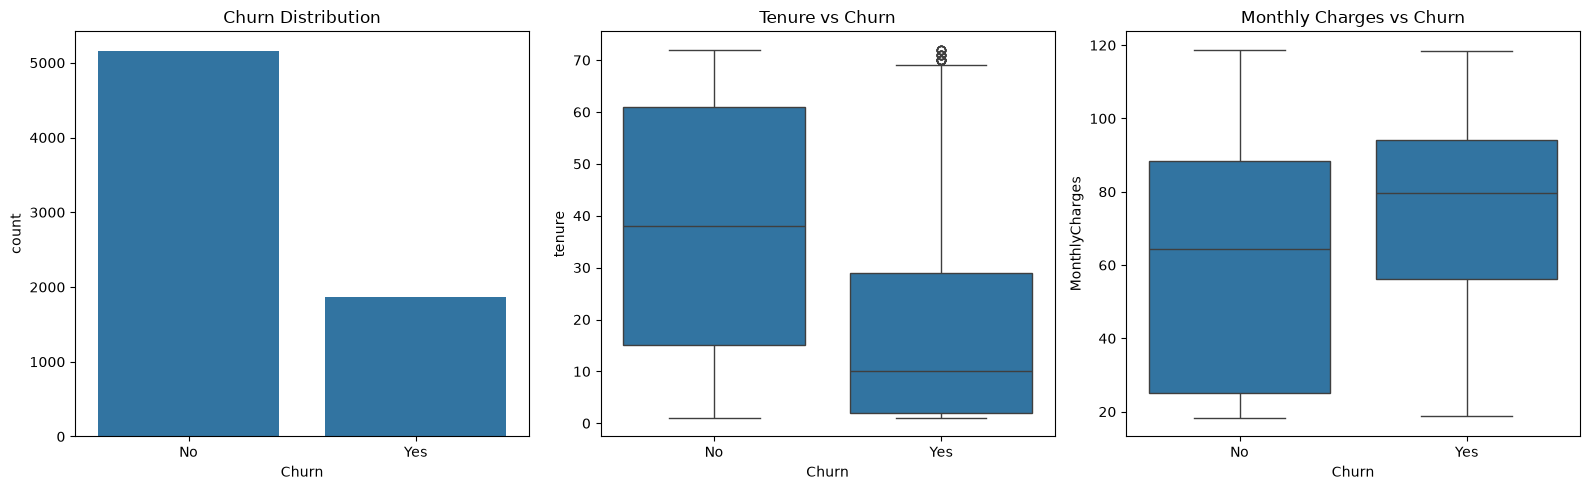

In [ ]:
#Dataset Distribution
print("Churn Distribution:")
display(df["Churn"].value_counts())

print("\nChurn Percentage:")
display(df["Churn"].value_counts(normalize=True).mul(100).round(2))

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

sns.countplot(data=df, x="Churn", ax=axes[0])
axes[0].set_title("Churn Distribution")

sns.boxplot(data=df, x="Churn", y="tenure", ax=axes[1])
axes[1].set_title("Tenure vs Churn")

sns.boxplot(data=df, x="Churn", y="MonthlyCharges", ax=axes[2])
axes[2].set_title("Monthly Charges vs Churn")

plt.tight_layout()
plt.show()

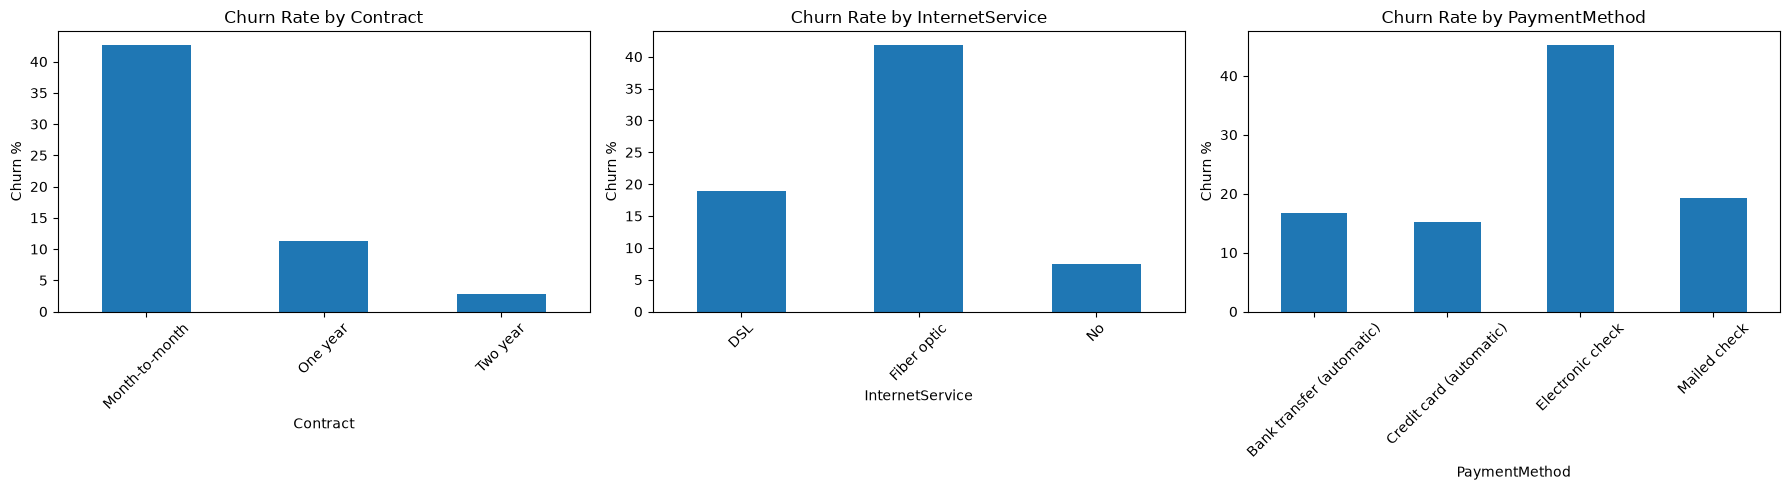

In [ ]:
#By each features
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, col in zip(
    axes,
    ["Contract", "InternetService", "PaymentMethod"]
):
    churn_rate = pd.crosstab(
        df[col],
        df["Churn"],
        normalize="index"
    ) * 100

    churn_rate["Yes"].plot(
        kind="bar",
        ax=ax
    )

    ax.set_title(f"Churn Rate by {col}")
    ax.set_ylabel("Churn %")
    ax.set_xlabel(col)
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

In [7]:
df["AvgMonthlyCharges"] = (
    df["TotalCharges"] /
    df["tenure"].replace(0, np.nan)
)

df["AvgMonthlyCharges"] = (
    df["AvgMonthlyCharges"]
    .fillna(df["MonthlyCharges"])
)

service_cols = [
    "PhoneService",
    "MultipleLines",
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies"
]

df["NumServices"] = (
    df[service_cols]
    .eq("Yes")
    .sum(axis=1)
)

display(
    df[
        [
            "tenure",
            "MonthlyCharges",
            "TotalCharges",
            "AvgMonthlyCharges",
            "NumServices"
        ]
    ].head()
)

,tenure,MonthlyCharges,TotalCharges,AvgMonthlyCharges,NumServices
0,1,29.85,29.85,29.850000,1
1,34,56.95,1889.50,55.573529,3
2,2,53.85,108.15,54.075000,3
3,45,42.30,1840.75,40.905556,3
4,2,70.70,151.65,75.825000,1


In [8]:
df["Churn"] = df["Churn"].map({
    "No": 0,
    "Yes": 1
})

categorical_cols = df.select_dtypes(
    include="object"
).columns

df_encoded = pd.get_dummies(
    df,
    columns=categorical_cols,
    drop_first=True,
    dtype=int
)

X = df_encoded.drop(columns="Churn")
y = df_encoded["Churn"]

from sklearn.model_selection import train_test_split

X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.40,
    random_state=42,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

C:\Users\ADS2609027\AppData\Local\Temp\4\ipykernel_8748\2532407101.py:6: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df.select_dtypes(


Train: (4219, 7063)
Validation: (1406, 7063)
Test: (1407, 7063)


In [9]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

print("Scaling completed.")
print("Train shape:", X_train_scaled.shape)
print("Validation shape:", X_val_scaled.shape)
print("Test shape:", X_test_scaled.shape)

Scaling completed.
Train shape: (4219, 7063)
Validation shape: (1406, 7063)
Test shape: (1407, 7063)


In [10]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix


class LogisticRegressionScratch:

    def __init__(self, learning_rate=0.01, epochs=1000):
        self.learning_rate = learning_rate
        self.epochs = epochs
        self.weights = None
        self.bias = 0
        self.cost_history = []

    # Sigmoid Function
    def sigmoid(self, z):
        z = np.clip(z, -500, 500)
        return 1 / (1 + np.exp(-z))

    # Training
    def fit(self, X, y):

        n_samples, n_features = X.shape

        # Initialize parameters
        self.weights = np.zeros(n_features)
        self.bias = 0

        self.cost_history = []

        for i in range(self.epochs):

            # Linear combination
            z = np.dot(X, self.weights) + self.bias

            # Sigmoid probability
            y_pred = self.sigmoid(z)

            # Negative Log-Likelihood / Binary Cross Entropy
            epsilon = 1e-15
            y_pred = np.clip(y_pred, epsilon, 1 - epsilon)

            cost = -np.mean(
                y * np.log(y_pred) +
                (1 - y) * np.log(1 - y_pred)
            )

            self.cost_history.append(cost)

            # Gradients
            dw = (1 / n_samples) * np.dot(
                X.T, (y_pred - y)
            )

            db = (1 / n_samples) * np.sum(
                y_pred - y
            )

            # Gradient Descent
            self.weights -= self.learning_rate * dw
            self.bias -= self.learning_rate * db

        return self

    # Probability prediction
    def predict_proba(self, X):

        z = np.dot(X, self.weights) + self.bias

        return self.sigmoid(z)

    # Class prediction
    def predict(self, X, threshold=0.5):

        probabilities = self.predict_proba(X)

        return (probabilities >= threshold).astype(int)

In [11]:
model = LogisticRegressionScratch(
    learning_rate=0.01,
    epochs=1000
)

model.fit(
    X_train_scaled,
    y_train.values
)

print("Training completed.")

Training completed.


In [14]:
y_train_pred = model.predict(X_train_scaled)
y_val_pred = model.predict(X_val_scaled)
y_test_pred = model.predict(X_test_scaled)
y_test_prob = model.predict_proba(X_test_scaled)

print("First 10 predicted probabilities:")
print(y_test_prob[:10])

First 10 predicted probabilities:
[0.20652838 0.43937959 0.16989621 0.10996313 0.59660097 0.76536624
 0.50546095 0.62341239 0.14659162 0.45495239]


In [15]:
accuracy = accuracy_score(y_test, y_test_pred)

precision = precision_score(
    y_test,
    y_test_pred,
    zero_division=0
)

recall = recall_score(
    y_test,
    y_test_pred,
    zero_division=0
)

f1 = f1_score(
    y_test,
    y_test_pred,
    zero_division=0
)

print("Logistic Regression Results")
print("---------------------------")

print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1 Score  : {f1:.4f}")

Logistic Regression Results
---------------------------
Accuracy  : 0.7982
Precision : 0.6236
Recall    : 0.6070
F1 Score  : 0.6152


Confusion Matrix:
[[896 137]
 [147 227]]


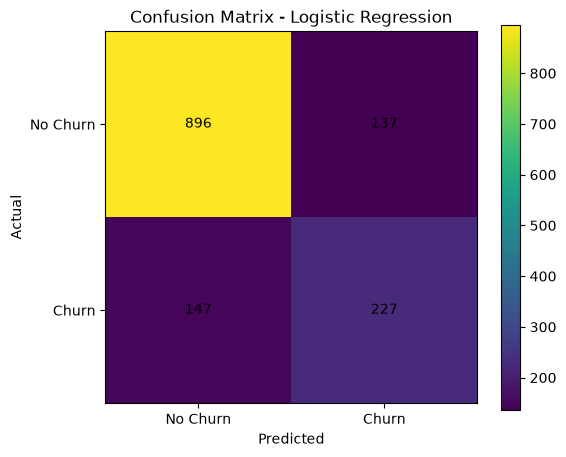

In [16]:
cm = confusion_matrix(y_test, y_test_pred)

print("Confusion Matrix:")
print(cm)
plt.figure(figsize=(6, 5))

plt.imshow(cm)

plt.title("Confusion Matrix - Logistic Regression")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.xticks(
    [0, 1],
    ["No Churn", "Churn"]
)

plt.yticks(
    [0, 1],
    ["No Churn", "Churn"]
)

for i in range(2):
    for j in range(2):
        plt.text(
            j,
            i,
            cm[i, j],
            ha="center",
            va="center"
        )

plt.colorbar()
plt.show()

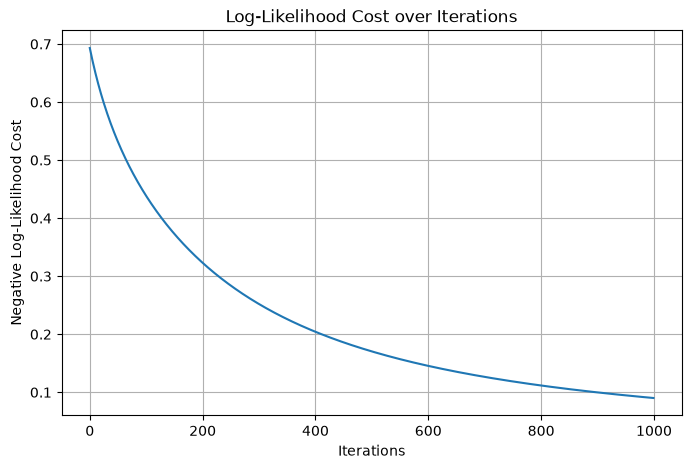

In [17]:
plt.figure(figsize=(8, 5))

plt.plot(
    model.cost_history
)

plt.xlabel("Iterations")
plt.ylabel("Negative Log-Likelihood Cost")
plt.title("Log-Likelihood Cost over Iterations")

plt.grid(True)

plt.show()

In [18]:
learning_rates = [0.001, 0.01, 0.1, 1.0]

models = {}
results = {}

for lr in learning_rates:

    model_lr = LogisticRegressionScratch(
        learning_rate=lr,
        epochs=1000
    )

    model_lr.fit(
        X_train_scaled,
        y_train.values
    )

    y_val_pred_lr = model_lr.predict(
        X_val_scaled
    )

    val_accuracy = accuracy_score(
        y_val,
        y_val_pred_lr
    )

    models[lr] = model_lr
    results[lr] = val_accuracy

    print(
        f"Learning Rate: {lr}"
    )

    print(
        f"Validation Accuracy: "
        f"{val_accuracy * 100:.2f}%"
    )

    print(
        f"Final Cost: "
        f"{model_lr.cost_history[-1]:.4f}"
    )

    print("---------------------------")

Learning Rate: 0.001
Validation Accuracy: 73.33%
Final Cost: 0.4386
---------------------------
Learning Rate: 0.01
Validation Accuracy: 78.95%
Final Cost: 0.0901
---------------------------
Learning Rate: 0.1
Validation Accuracy: 78.88%
Final Cost: 0.0086
---------------------------
Learning Rate: 1.0
Validation Accuracy: 78.95%
Final Cost: 0.0008
---------------------------


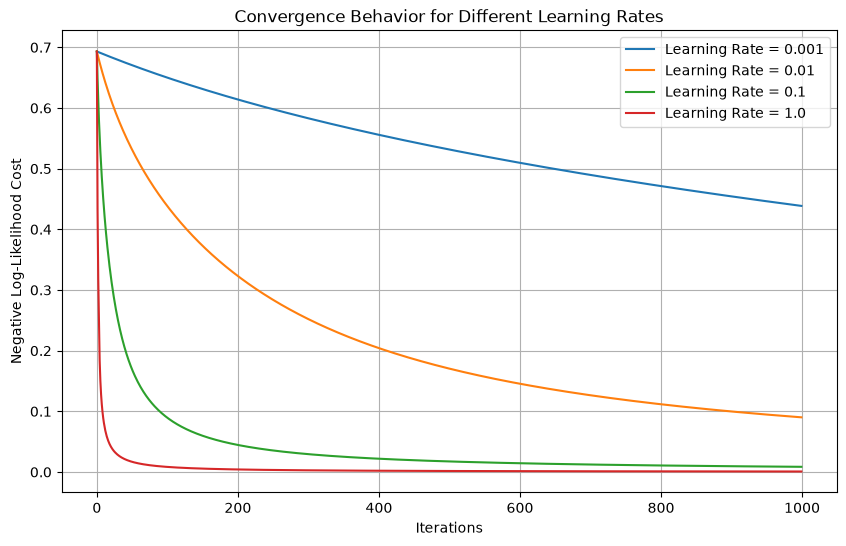

In [19]:
plt.figure(figsize=(10, 6))

for lr in learning_rates:

    plt.plot(
        models[lr].cost_history,
        label=f"Learning Rate = {lr}"
    )

plt.xlabel("Iterations")
plt.ylabel("Negative Log-Likelihood Cost")

plt.title(
    "Convergence Behavior for Different Learning Rates"
)

plt.legend()

plt.grid(True)

plt.show()

In [20]:
best_lr = max(
    results,
    key=results.get
)

print(
    "Best Learning Rate:",
    best_lr
)

print(
    "Best Validation Accuracy:",
    f"{results[best_lr] * 100:.2f}%"
)

Best Learning Rate: 0.01
Best Validation Accuracy: 78.95%


In [21]:
best_model = models[best_lr]

y_test_pred_best = best_model.predict(
    X_test_scaled
)

final_accuracy = accuracy_score(
    y_test,
    y_test_pred_best
)

final_precision = precision_score(
    y_test,
    y_test_pred_best,
    zero_division=0
)

final_recall = recall_score(
    y_test,
    y_test_pred_best,
    zero_division=0
)

final_f1 = f1_score(
    y_test,
    y_test_pred_best,
    zero_division=0
)

print("\nFinal Test Results")
print("==================")

print(f"Learning Rate: {best_lr}")
print(f"Accuracy     : {final_accuracy * 100:.2f}%")
print(f"Precision    : {final_precision * 100:.2f}%")
print(f"Recall       : {final_recall * 100:.2f}%")
print(f"F1 Score     : {final_f1 * 100:.2f}%")


Final Test Results
Learning Rate: 0.01
Accuracy     : 79.82%
Precision    : 62.36%
Recall       : 60.70%
F1 Score     : 61.52%


In [22]:
from sklearn.metrics import confusion_matrix

# Predictions from best model
y_pred = best_model.predict(X_test_scaled)

cm = confusion_matrix(y_test, y_pred)

TN, FP, FN, TP = cm.ravel()

print(cm)
print(f"TN={TN}, FP={FP}, FN={FN}, TP={TP}")

[[896 137]
 [147 227]]
TN=896, FP=137, FN=147, TP=227


In [23]:
accuracy = (TP + TN) / (TP + TN + FP + FN)

precision = TP / (TP + FP)

recall = TP / (TP + FN)

f1 = 2 * (precision * recall) / (precision + recall)

print("Manual Metrics")
print("----------------")
print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1 Score : {f1:.4f}")

Manual Metrics
----------------
Accuracy : 0.7982
Precision: 0.6236
Recall   : 0.6070
F1 Score : 0.6152


In [24]:
from sklearn.metrics import confusion_matrix

# Predictions from best model
y_pred = best_model.predict(X_test_scaled)

cm = confusion_matrix(y_test, y_pred)

TN, FP, FN, TP = cm.ravel()

print(cm)
print(f"TN={TN}, FP={FP}, FN={FN}, TP={TP}")

[[896 137]
 [147 227]]
TN=896, FP=137, FN=147, TP=227


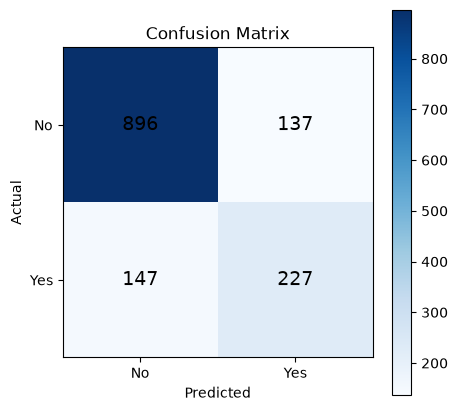

In [26]:
import matplotlib.pyplot as plt

plt.figure(figsize=(5,5))
plt.imshow(cm, cmap="Blues")

plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.xticks([0,1],["No","Yes"])
plt.yticks([0,1],["No","Yes"])

for i in range(2):
    for j in range(2):
        plt.text(j,i,cm[i,j],
                 ha="center",
                 va="center",
                 fontsize=14)

plt.colorbar()
plt.show()

AUC: 0.8398530317697792


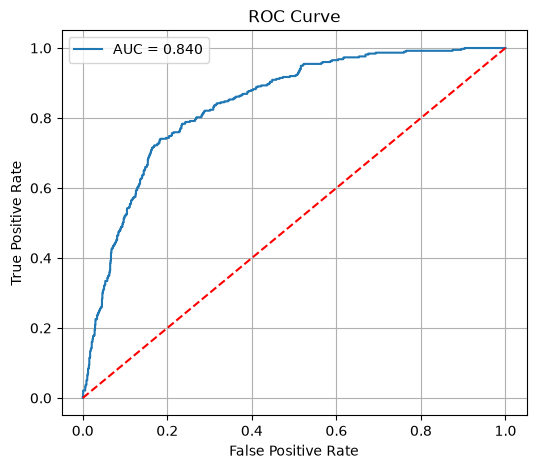

In [28]:
from sklearn.metrics import roc_curve, auc

# Probability prediction
y_prob = best_model.predict_proba(X_test_scaled)

fpr, tpr, thresholds = roc_curve(y_test, y_prob)

roc_auc = auc(fpr, tpr)

print("AUC:", roc_auc)
plt.figure(figsize=(6,5))

plt.plot(fpr, tpr, label=f"AUC = {roc_auc:.3f}")
plt.plot([0,1],[0,1],"--", color="red")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")

plt.legend()
plt.grid()

plt.show()

In [29]:
feature_names = X.columns

coefficients = best_model.weights

importance = coefficients

import pandas as pd

coef_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": importance
})

coef_df["Absolute"] = coef_df["Coefficient"].abs()

coef_df = coef_df.sort_values(
    "Absolute",
    ascending=False
)

coef_df.head(10)

,Feature,Coefficient,Absolute
1,tenure,-0.269130,0.269130
7043,InternetService_Fiber optic,0.207625,0.207625
3,TotalCharges,-0.186241,0.186241
7058,Contract_Two year,-0.180581,0.180581
7061,PaymentMethod_Electronic check,0.176016,0.176016
7057,Contract_One year,-0.158303,0.158303
7052,TechSupport_Yes,-0.153745,0.153745
7046,OnlineSecurity_Yes,-0.151442,0.151442
7059,PaperlessBilling_Yes,0.115705,0.115705
7048,OnlineBackup_Yes,-0.094440,0.094440


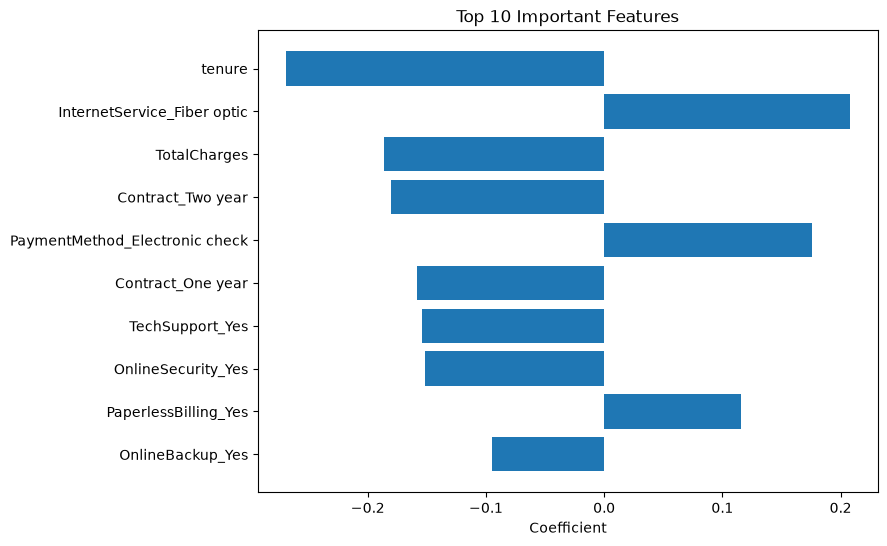

In [30]:
top10 = coef_df.head(10)

plt.figure(figsize=(8,6))

plt.barh(
    top10["Feature"],
    top10["Coefficient"]
)

plt.xlabel("Coefficient")
plt.title("Top 10 Important Features")

plt.gca().invert_yaxis()

plt.show()

Churn
0    2555.203283
1    1531.608828
Name: CLV, dtype: float64


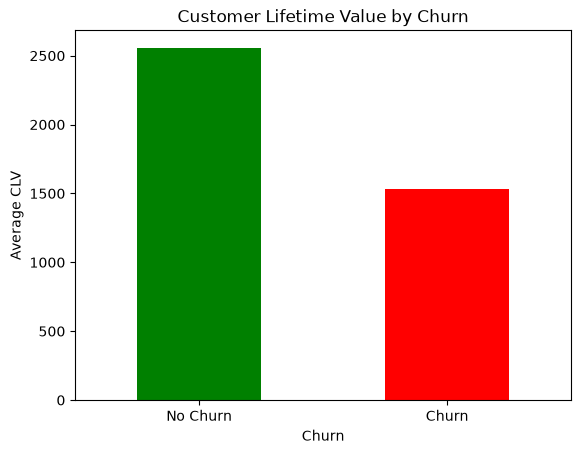

In [33]:
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

df["TotalCharges"] = df["TotalCharges"].fillna(0)

df["CLV"] = df["MonthlyCharges"] * df["tenure"]

clv_summary = df.groupby("Churn")["CLV"].mean()

print(clv_summary)

clv_summary.plot(
    kind="bar",
    color=["green","red"]
)

plt.xticks([0,1],["No Churn","Churn"], rotation=0)
plt.ylabel("Average CLV")
plt.title("Customer Lifetime Value by Churn")

plt.show()

In [34]:
churn_customers = df[df["Churn"] == 1]

total_loss = churn_customers["CLV"].sum()

avg_loss = churn_customers["CLV"].mean()

print(f"Total CLV Loss : ${total_loss:.2f}")
print(f"Average CLV Loss per Customer : ${avg_loss:.2f}")

Total CLV Loss : $2862576.90
Average CLV Loss per Customer : $1531.61
